# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 6      # мой номер в списке группы
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: /home/koksic/Desktop/projectic/учеба/cv-2026-eskov/data
Вариант 06 уже на месте: /home/koksic/Desktop/projectic/учеба/cv-2026-eskov/data/variant_06


данные варианта: /home/koksic/Desktop/projectic/учеба/cv-2026-eskov/data/variant_06
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 4.14.0 | numpy 2.4.6 | pandas 3.1.0


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [3]:
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(json.dumps(variant_info, ensure_ascii=False, indent=2))
assert variant_info["variant"] == VARIANT, "номер в variant.json не совпадает с VARIANT"

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "строк в labels.csv")
labels.head()

{
  "variant": 6,
  "dataset_version": "v1",
  "source": "release",
  "breeds": [
    "British_Shorthair",
    "Russian_Blue",
    "german_shorthaired",
    "samoyed"
  ],
  "species": {
    "British_Shorthair": "cat",
    "Russian_Blue": "cat",
    "german_shorthaired": "dog",
    "samoyed": "dog"
  },
  "class_ids": {
    "British_Shorthair": 0,
    "Russian_Blue": 1,
    "german_shorthaired": 2,
    "samoyed": 3
  },
  "names_ru": {
    "British_Shorthair": "британская короткошёрстная",
    "Russian_Blue": "русская голубая",
    "german_shorthaired": "курцхаар (немецкая короткошёрстная легавая)",
    "samoyed": "самоедская собака"
  },
  "n_images": 800,
  "n_boxes": 399,
  "n_trimaps": 800,
  "per_breed": {
    "British_Shorthair": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "Russian_Blue": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "german_shorthaired": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
  

,filename,breed,species,class_id
0,British_Shorthair_2.jpg,British_Shorthair,cat,0
1,British_Shorthair_3.jpg,British_Shorthair,cat,0
2,British_Shorthair_6.jpg,British_Shorthair,cat,0
3,British_Shorthair_8.jpg,British_Shorthair,cat,0
4,British_Shorthair_9.jpg,British_Shorthair,cat,0


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [4]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

bgr = cv2.imread(str(example_path))
cy, cx = bgr.shape[0] // 2, bgr.shape[1] // 2
print("type :", type(bgr))
print("shape:", bgr.shape, "(высота, ширина, каналы)")
print("dtype:", bgr.dtype, "| min:", bgr.min(), "| max:", bgr.max())
print("пиксель в центре, BGR:", bgr[cy, cx])

german_shorthaired_48.jpg
type : <class 'numpy.ndarray'>
shape: (500, 386, 3) (высота, ширина, каналы)
dtype: uint8 | min: 0 | max: 255
пиксель в центре, BGR: [19 25 54]


пиксель в центре, RGB: [54 25 19]


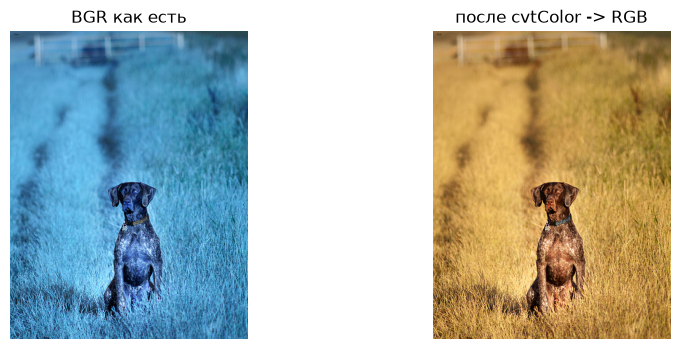

In [5]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
print("пиксель в центре, RGB:", rgb[cy, cx])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(bgr); plt.title("BGR как есть"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(rgb); plt.title("после cvtColor -> RGB"); plt.axis("off")
plt.show()
# matplotlib ждёт RGB, а OpenCV отдаёт BGR: красный и синий каналы меняются местами,
# поэтому рыжая шерсть без cvtColor выглядит синей.

Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [6]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)
print("gray:   ", gray.shape, gray.dtype)
print("resized:", resized.shape, resized.dtype)
print("flipped:", flipped.shape, flipped.dtype)

gray:    (500, 386) uint8
resized: (224, 224, 3) uint8
flipped: (500, 386, 3) uint8


In [7]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


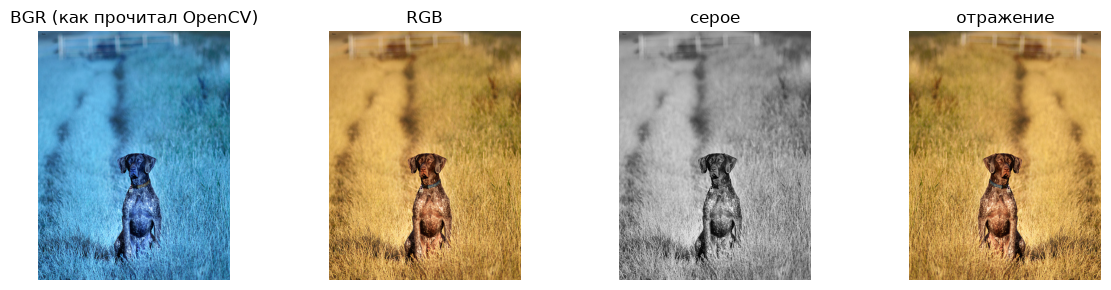

In [8]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR (как прочитал OpenCV)"); plt.axis("off")
plt.subplot(1, 4, 2); plt.imshow(rgb); plt.title("RGB"); plt.axis("off")
plt.subplot(1, 4, 3); plt.imshow(gray, cmap="gray"); plt.title("серое"); plt.axis("off")
plt.subplot(1, 4, 4); plt.imshow(flipped); plt.title("отражение"); plt.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [9]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"], rec["height"] = im.size

    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()

    lab = label_by_file.loc[p.name]
    rec["breed"] = lab["breed"]
    rec["species"] = lab["species"]

    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,British_Shorthair_10.jpg,.jpg,JPEG,RGB,233,350,True,British_Shorthair,cat
1,British_Shorthair_100.jpg,.jpg,JPEG,RGB,500,332,True,British_Shorthair,cat
2,British_Shorthair_101.jpg,.jpg,JPEG,RGB,500,333,True,British_Shorthair,cat
3,British_Shorthair_102.jpg,.jpg,JPEG,RGB,500,333,True,British_Shorthair,cat
4,British_Shorthair_103.jpg,.jpg,JPEG,RGB,500,333,True,British_Shorthair,cat


In [10]:
per_breed = info["breed"].value_counts()
info["aspect"] = info[["width", "height"]].max(axis=1) / info[["width", "height"]].min(axis=1)

summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
    "n_cats": int((info["species"] == "cat").sum()),
    "n_dogs": int((info["species"] == "dog").sum()),
    **{f"n_{b}": int(n) for b, n in per_breed.sort_index().items()},
    "breed_max_to_min": round(per_breed.max() / per_breed.min(), 2),
    "width_min": int(info["width"].min()),
    "width_median": float(info["width"].median()),
    "width_max": int(info["width"].max()),
    "height_min": int(info["height"].min()),
    "height_median": float(info["height"].median()),
    "height_max": int(info["height"].max()),
    "aspect_max": round(float(info["aspect"].max()), 2),
    "n_not_rgb": int((info["mode"] != "RGB").sum()),
    **{f"n_mode_{m}": int(n) for m, n in info.loc[info["mode"] != "RGB", "mode"].value_counts().items()},
    "n_jpg_not_jpeg": int(((info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")).sum()),
    "n_with_xml": int(info["has_xml"].sum()),
    "share_with_xml": round(float(info["has_xml"].mean()), 3),
}
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"], dtype=object)
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,6
1,n_files,800
2,n_breeds,4
3,n_cats,400
4,n_dogs,400
5,n_British_Shorthair,200
6,n_Russian_Blue,200
7,n_german_shorthaired,200
8,n_samoyed,200
9,breed_max_to_min,1.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [11]:
not_rgb = info[info["mode"] != "RGB"]
print(f"не в режиме RGB: {len(not_rgb)}")
print(not_rgb[["filename", "pil_format", "mode", "width", "height"]].to_string(index=False))

bad_fmt = info[info["pil_format"] != "JPEG"]
print(f"\nформат не JPEG при расширении .jpg: {len(bad_fmt)}")
print(bad_fmt[["filename", "pil_format", "mode"]].to_string(index=False))

не в режиме RGB: 0
Empty DataFrame
Columns: [filename, pil_format, mode, width, height]
Index: []

формат не JPEG при расширении .jpg: 0
Empty DataFrame
Columns: [filename, pil_format, mode]
Index: []


In [12]:
problem = pd.concat([bad_fmt, not_rgb]).drop_duplicates("filename")
if len(problem):
    pp = str(IMG_DIR / problem.iloc[0]["filename"])
    print(problem.iloc[0]["filename"], "| Pillow:", problem.iloc[0]["pil_format"], problem.iloc[0]["mode"])
    print("cv2.imread(p).shape                       :", cv2.imread(pp).shape)
    print("cv2.imread(p, cv2.IMREAD_UNCHANGED).shape :", cv2.imread(pp, cv2.IMREAD_UNCHANGED).shape)
else:
    # В моём варианте таких файлов нет: для сравнения беру фото из раздела 2 и trimap (одноканальный PNG)
    print("проблемных файлов нет")
    print(example_name, "cv2.imread(p).shape                       :", cv2.imread(str(example_path)).shape)
    print(example_name, "cv2.imread(p, cv2.IMREAD_UNCHANGED).shape :", cv2.imread(str(example_path), cv2.IMREAD_UNCHANGED).shape)
    tp = str(TRIMAP_DIR / (Path(example_name).stem + ".png"))
    print("trimap cv2.imread(p).shape                       :", cv2.imread(tp).shape)
    print("trimap cv2.imread(p, cv2.IMREAD_UNCHANGED).shape :", cv2.imread(tp, cv2.IMREAD_UNCHANGED).shape)

проблемных файлов нет
german_shorthaired_48.jpg cv2.imread(p).shape                       : (500, 386, 3)
german_shorthaired_48.jpg cv2.imread(p, cv2.IMREAD_UNCHANGED).shape : (500, 386, 3)
trimap cv2.imread(p).shape                       : (500, 386, 3)
trimap cv2.imread(p, cv2.IMREAD_UNCHANGED).shape : (500, 386)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [13]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

xml_example = info[info["has_xml"]].sort_values("filename").iloc[0]["filename"]
stem = Path(xml_example).stem
print(xml_example, "боксы:", read_boxes(XML_DIR / (stem + ".xml")))

trimap = cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
vals, cnts = np.unique(trimap, return_counts=True)
print("trimap shape:", trimap.shape, "| значения:", vals, "| пикселей:", cnts)

British_Shorthair_10.jpg боксы: [(83, 29, 197, 142)]
trimap shape: (350, 233) | значения: [1 2 3] | пикселей: [26302 40923 14325]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

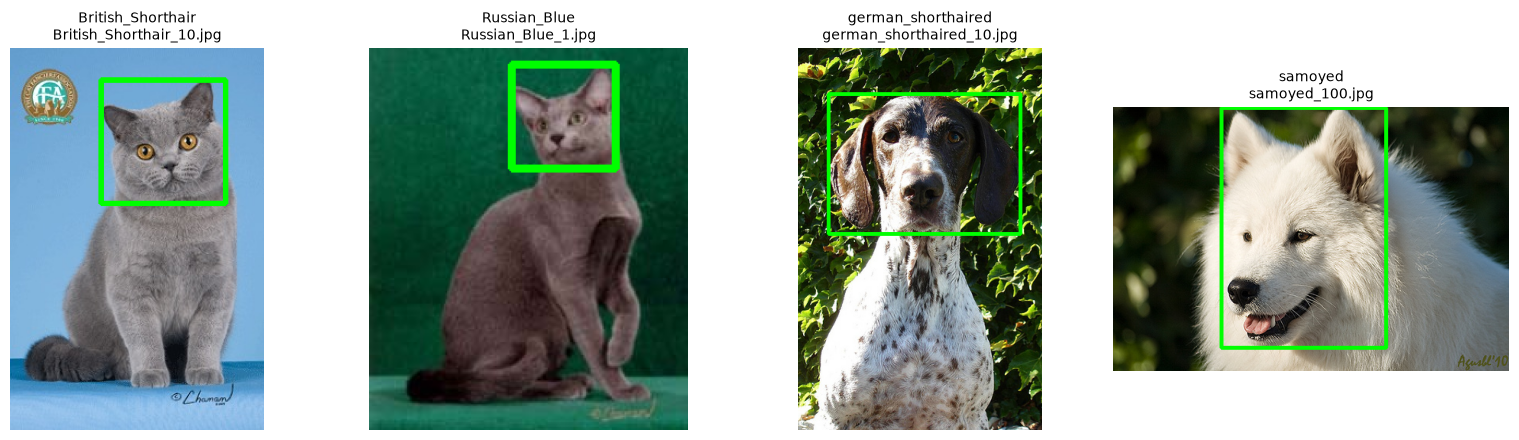

In [14]:
breeds = variant_info["breeds"]
fig = plt.figure(figsize=(4 * len(breeds), 4.5))
for i, breed in enumerate(breeds):
    cand = info[(info["breed"] == breed) & info["has_xml"] & (info["mode"] == "RGB")].sort_values("filename")
    fn = cand.iloc[0]["filename"]
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / fn)), cv2.COLOR_BGR2RGB)
    for x0, y0, x1, y1 in read_boxes(XML_DIR / (Path(fn).stem + ".xml")):
        cv2.rectangle(img, (x0, y0), (x1, y1), (0, 255, 0), 3)
    plt.subplot(1, len(breeds), i + 1)
    plt.imshow(img)
    plt.title(f"{breed}\n{fn}", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "samples_grid.png", dpi=110)
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [15]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

              metric  value
             variant      6
             n_files    800
            n_breeds      4
              n_cats    400
              n_dogs    400
 n_British_Shorthair    200
      n_Russian_Blue    200
n_german_shorthaired    200
           n_samoyed    200
    breed_max_to_min    1.0
           width_min    194
        width_median  500.0
           width_max   1200
          height_min    196
       height_median  375.0
          height_max    900
          aspect_max   2.38
           n_not_rgb      0
      n_jpg_not_jpeg      0
          n_with_xml    399
      share_with_xml  0.499
не хватает: ничего, все 3 файла на месте


In [16]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)